## Imports and setup

In [1]:
import torch
import os
import numpy as np
from transformers import BertModel, BertConfig, BertForSequenceClassification
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from scipy.spatial.distance import directed_hausdorff

import warnings

/u/brenow1/miniconda3/envs/torch_cuda_1.12/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

### Auxiliary function definitions

In [3]:
def load_checkpoints_from_folder(checkpoints_directory, ModelClass, prefix="checkpoint_", sort=True):
    checkpoint_files = [f for f in os.listdir(checkpoints_directory) if f.startswith(prefix)]
    if sort:
        checkpoint_files = sorted(checkpoint_files)
    # Load all of the checkpoints.
    checkpoints = []
    for checkpoint_file in checkpoint_files:
        model = ModelClass(BertConfig())
        weights = torch.load(os.path.join(checkpoints_directory, checkpoint_file), map_location=torch.device(device))
        model.load_state_dict(weights)
        checkpoints.append(model)
    return checkpoint_files, checkpoints

In [4]:
def get_flattened_array_weights(checkpoint_model):
    return torch.nn.utils.parameters_to_vector(checkpoint_model.parameters()).detach().numpy()

In [5]:
def compare_checkpoints_cosine_similarity(checkpoints_directory, ModelClass):
    checkpoint_files, checkpoints = load_checkpoints_from_folder(checkpoints_directory, ModelClass)
    
    # Convert the weights of each checkpoint to a 1-D tensor.
    flattened_weights = [get_flattened_array_weights(checkpoint) for checkpoint in checkpoints]

    # Compute the pairwise cosine similarity between all checkpoints.
    for i, weights_i in enumerate(flattened_weights):
        for j, weights_j in enumerate(flattened_weights):
            if j > i:  # To avoid double calculation
                similarity = cosine_similarity(weights_i.reshape(1, -1), weights_j.reshape(1, -1))
                print(f"Cosine similarity between {checkpoint_files[i]} and {checkpoint_files[j]}: {similarity[0][0]}")

In [6]:
checkpoint_files, checkpoints = load_checkpoints_from_folder("checkpoints/regular_training_001", BertForSequenceClassification)
flattened_weights = [get_flattened_array_weights(checkpoint) for checkpoint in checkpoints]

In [7]:
# TODO save for later

## Distance Analysis

### PCA Analysis

In [8]:
pca = PCA(n_components=2)
components = pca.fit_transform(flattened_weights)

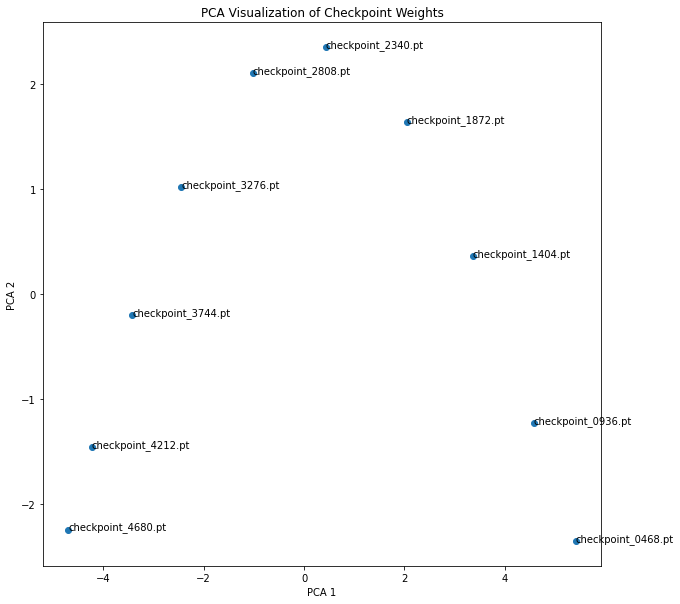

In [9]:
# Visualize using matplotlib
plt.figure(figsize=(10, 10))
plt.scatter(components[:, 0], components[:, 1])

# Add labels to the points
for i, checkpoint_file in enumerate(checkpoint_files):
    plt.annotate(checkpoint_file, (components[i, 0], components[i, 1]))

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('PCA Visualization of Checkpoint Weights')
plt.show()

### Checkpoint distance

In [10]:
def compare_checkpoints_similarity(checkpoint_files,flattened_weights,sim, sim_name):
    # Compute the pairwise cosine similarity between all checkpoints.
    for i, weights_i in enumerate(flattened_weights):
        for j, weights_j in enumerate(flattened_weights):
            if j > i:  # To avoid double calculation
                similarity = sim(weights_i.reshape(1, -1), weights_j.reshape(1, -1))
                print(f"{sim_name} similarity between {checkpoint_files[i]} and {checkpoint_files[j]}: {similarity}")
                print(f"{sim_name} similarity between {checkpoint_files[i]} and {checkpoint_files[j]}: {similarity}")

In [11]:
def plot_checkpoints_similarity(checkpoint_files,flattened_weights,sim, sim_name, fmt=".2f"):
    # Compute pairwise L1 distances
    distances = np.zeros((len(flattened_weights), len(flattened_weights)))
    for i, weights_i in enumerate(tqdm(flattened_weights, desc="Comparing")):
        for j, weights_j in enumerate(flattened_weights):
            if j >= i:  # Compute half of the matrix (it's symmetrical)
                distance = sim(weights_i.reshape(1, -1), weights_j.reshape(1, -1))
                distances[i, j] = distance
                distances[j, i] = distance  # Use symmetry to avoid double computation
    
    # Plot the distances as a heatmap
    plt.figure(figsize=(10, 10))
    sns.heatmap(distances, annot=True, fmt=fmt, xticklabels=checkpoint_files, yticklabels=checkpoint_files)
    plt.title(f'{sim_name} distances between checkpoints')
    plt.show()

In [12]:
l1_distance = lambda weights_i, weights_j: np.sum(np.abs(weights_i - weights_j))

In [13]:
l2_distance = lambda weights_i, weights_j: np.linalg.norm(weights_i - weights_j)
# np.sqrt(np.sum((weights_i - weights_j)**2))

In [14]:
minus_cosine_distance = lambda weights_i, weights_j: 1 - cosine_similarity(weights_i, weights_j)[0][0]

In [15]:
def directed_hausdorff(arr1, arr2):
    """
    Compute the directed Hausdorff distance between two 1D arrays

    Parameters:
    arr1 (numpy.ndarray): First array
    arr2 (numpy.ndarray): Second array

    Returns:
    float: The directed Hausdorff distance from arr1 to arr2
    """
    # Initialize maximum distance to 0
    max_distance = 0

    # For each point in arr1
    for point1 in arr1:
        # Compute the minimum distance to any point in arr2
        min_distance = np.min(np.abs(arr2 - point1))
        # Update maximum distance if necessary
        max_distance = max(max_distance, min_distance)

    return max_distance

In [16]:
def hausdorff_dist(weights_i, weights_j):
    if len(weights_i.shape) < 2 and len(weights_j.shape) < 2:
        weights_i = weights_i.reshape(-1,1)
        weights_j = weights_j.reshape(-1,1)
    return max(directed_hausdorff(weights_i, weights_j)[0], directed_hausdorff(weights_j, weights_i)[0])


In [17]:
def directed_hausdorff_gpu(arr1, arr2):
    """
    Compute the directed Hausdorff distance between two 1D arrays

    Parameters:
    arr1 (np.array): First array
    arr2 (np.array): Second array

    Returns:
    float: The directed Hausdorff distance from arr1 to arr2
    """
    arr1 = torch.tensor(arr1, device=device)
    arr2 = torch.tensor(arr2, device=device)

    
    # Use broadcasting to compute all pairwise distances
    arr1 = arr1.unsqueeze(1)  # Adds an extra dimension
    distances = torch.abs(arr1 - arr2)  # Pairwise distances

    # Get the minimum distance for each point in arr1
    min_distances, _ = torch.min(distances, dim=1)

    # Return the maximum of these minimum distances
    max_distance, _ = torch.max(min_distances, dim=0)

    return max_distance.item()

# Set device to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

- Global Distance

Here we flatten the weights of the model into a tensor and calculate a few simple distances

Comparing: 100%|██████████| 10/10 [00:19<00:00,  1.94s/it]


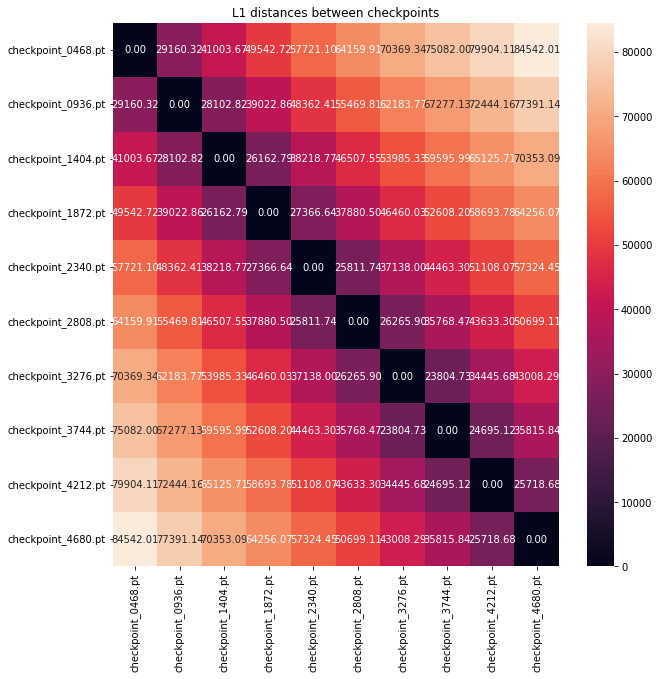

In [18]:
plot_checkpoints_similarity(checkpoint_files, flattened_weights, l1_distance, "L1")

Comparing: 100%|██████████| 10/10 [00:10<00:00,  1.04s/it]


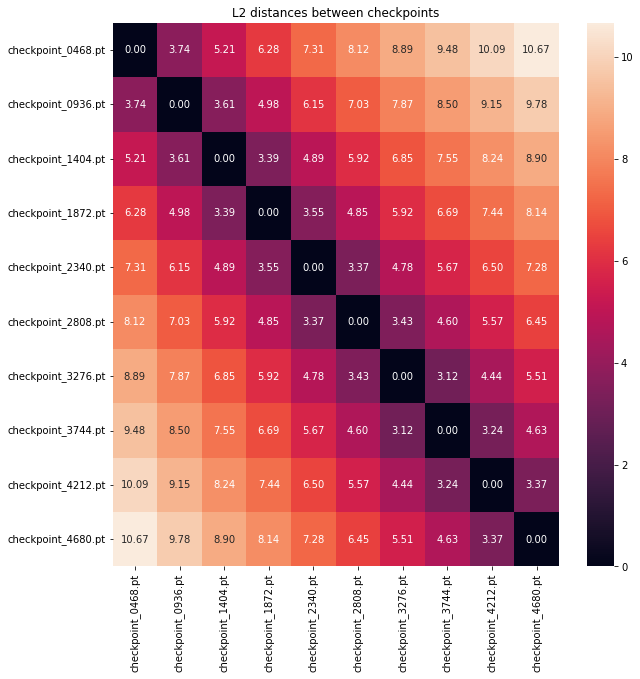

In [19]:
plot_checkpoints_similarity(checkpoint_files, flattened_weights, l2_distance, "L2")

Comparing: 100%|██████████| 10/10 [00:38<00:00,  3.89s/it]


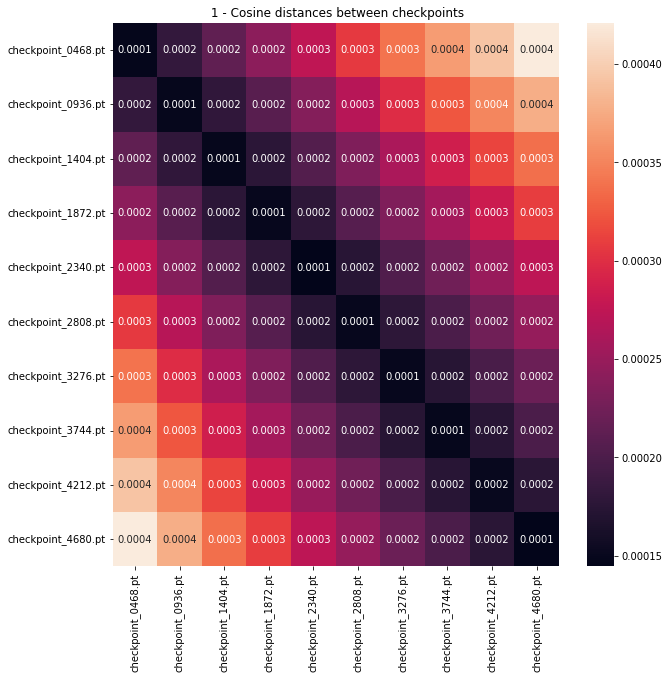

In [20]:
plot_checkpoints_similarity(checkpoint_files, flattened_weights, minus_cosine_distance, " 1 - Cosine", fmt=".4f")

In [21]:
# plot_checkpoints_similarity(checkpoint_files, flattened_weights, hausdorff_dist, "Hausdorff Global")

- Distance by layers

Here we flatten the weights of each layer of the model into a tensor and calculate a few simple distances. We then calculat the mean among the layers 

In [22]:
def plot_checkpoints_similarity_per_layer_average(checkpoint_files, checkpoints, sim, sim_name, fmt=".2f"):

    # Initialize an empty array for the distances
    dist_matrix = np.zeros((len(checkpoints), len(checkpoints)))
    
    # Compute pairwise Hausdorff distances for each layer
    for i, checkpoint_i in enumerate(tqdm(checkpoints)):
        for j, checkpoint_j in enumerate(checkpoints):
            if j >= i:  # To avoid double calculation
                layer_distances = []
                for (name_i, param_i), (name_j, param_j) in zip(checkpoint_i.named_parameters(), checkpoint_j.named_parameters()):
                    if name_i == name_j:  # Should always be True
                        # Flatten the weights to 1D vectors
                        weights_i = param_i.detach().numpy().flatten().reshape(1, -1)
                        weights_j = param_j.detach().numpy().flatten().reshape(1, -1)
                        # Compute Hausdorff distance for this layer
                        distance = sim(weights_i, weights_j)
                        layer_distances.append(distance)
                        
                # Sum or average the layer distances to get a single distance value for the pair of checkpoints
                dist_matrix[i, j] = sum(layer_distances)/len(layer_distances)
                dist_matrix[j, i] = dist_matrix[i, j]  # The distance is symmetric
    
    # Plot the distances as a heatmap
    plt.figure(figsize=(10, 10))
    sns.heatmap(dist_matrix, annot=True, fmt=fmt, xticklabels=checkpoint_files, yticklabels=checkpoint_files)
    plt.title(f'{sim_name} distances between checkpoints')
    plt.show()

In [28]:
def plot_checkpoints_similarity_per_layer(checkpoint_files, checkpoints, sim, sim_name, layer_num, fmt=".2f"):

    # Initialize an empty array for the distances
    dist_matrix = np.zeros((len(checkpoints), len(checkpoints)))
    
    # Compute pairwise distances for each layer
    for i, checkpoint_i in enumerate(tqdm(checkpoints)):
        for j, checkpoint_j in enumerate(checkpoints):
            if j >= i:  # To avoid double calculation
                layer_distances = []
                (name_i, param_i), (name_j, param_j) = list(zip(checkpoint_i.named_parameters(), checkpoint_j.named_parameters()))[layer_num]
                if name_i == name_j:  # Should always be True
                    # Flatten the weights to 1D vectors
                    weights_i = param_i.detach().numpy().flatten().reshape(1, -1)
                    weights_j = param_j.detach().numpy().flatten().reshape(1, -1)
                    # Compute Hausdorff distance for this layer
                    distance = sim(weights_i, weights_j)
                        
                    # Sum or average the layer distances to get a single distance value for the pair of checkpoints
                    dist_matrix[i, j] = distance
                    dist_matrix[j, i] = dist_matrix[i, j]  # The distance is symmetric
    
    # Plot the distances as a heatmap
    plt.figure(figsize=(10, 10))
    sns.heatmap(dist_matrix, annot=True, fmt=fmt, xticklabels=checkpoint_files, yticklabels=checkpoint_files)
    plt.title(f'{sim_name} distances between checkpoints of layer {name_i}')
    plt.show()

In [24]:
def get_num_layers(checkpoint):
    return len(list(checkpoint.named_parameters()))

In [25]:
def plot_hausdorff_per_layer(checkpoint_files, checkpoints):
    # Initialize an empty array for the distances
    hausdorff_distances = np.zeros((len(checkpoints), len(checkpoints)))
    
    # Compute pairwise Hausdorff distances for each layer
    for i, checkpoint_i in enumerate(tqdm(checkpoints)):
        for j, checkpoint_j in enumerate(checkpoints):
            if j >= i:  # To avoid double calculation
                layer_distances = []
                for (name_i, param_i), (name_j, param_j) in zip(checkpoint_i.named_parameters(), checkpoint_j.named_parameters()):
                    if name_i == name_j:  # Should always be True
                        # Flatten the weights to 1D vectors
                        weights_i = param_i.detach().numpy().flatten().reshape(1, -1)
                        weights_j = param_j.detach().numpy().flatten().reshape(1, -1)
                        # Compute Hausdorff distance for this layer
                        hausdorff_distance = hausdorff_dist(weights_i, weights_j)
                        layer_distances.append(hausdorff_distance)
                # Sum or average the layer distances to get a single distance value for the pair of checkpoints
                hausdorff_distances[i, j] = sum(layer_distances)
                hausdorff_distances[j, i] = hausdorff_distances[i, j]  # The distance is symmetric
    
    # Plot the distances as a heatmap
    plt.figure(figsize=(10, 10))
    sns.heatmap(hausdorff_distances, annot=True, fmt=".2f", xticklabels=checkpoint_files, yticklabels=checkpoint_files)
    plt.title('Hausdorff distances between checkpoints')
    plt.show()

In [26]:
# plot_hausdorff_per_layer(checkpoint_files, checkpoints)

100%|██████████| 10/10 [00:00<00:00, 166.41it/s]


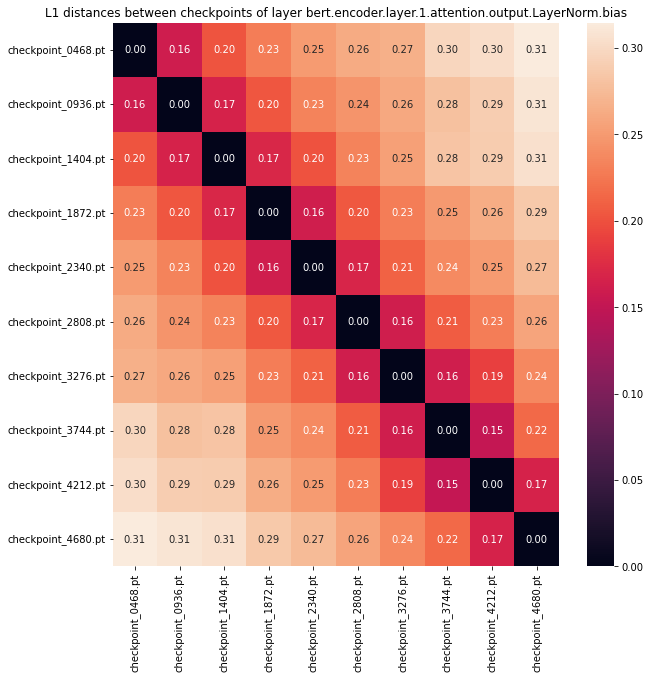

In [30]:
plot_checkpoints_similarity_per_layer(checkpoint_files, checkpoints, l1_distance, 'L1', layer_num=30)

100%|██████████| 10/10 [00:00<00:00, 164.43it/s]


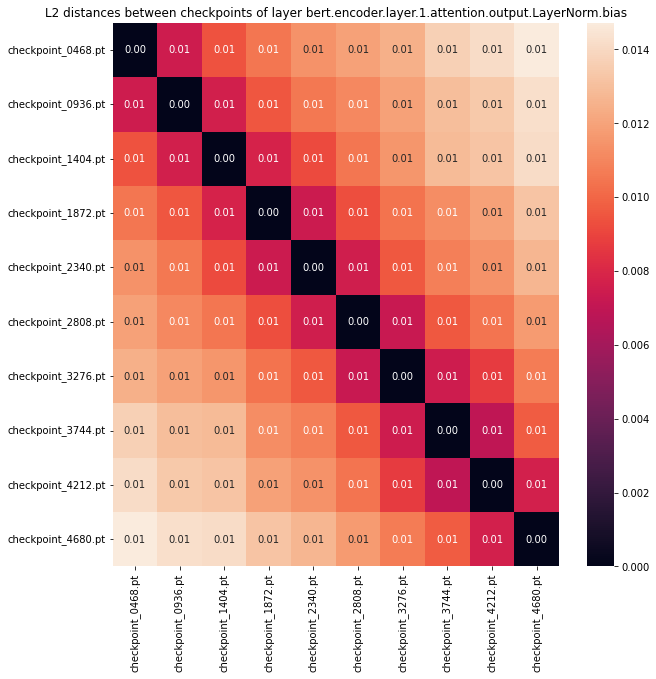

In [31]:
plot_checkpoints_similarity_per_layer(checkpoint_files, checkpoints, l2_distance, 'L2', layer_num=30)

100%|██████████| 10/10 [00:00<00:00, 117.12it/s]


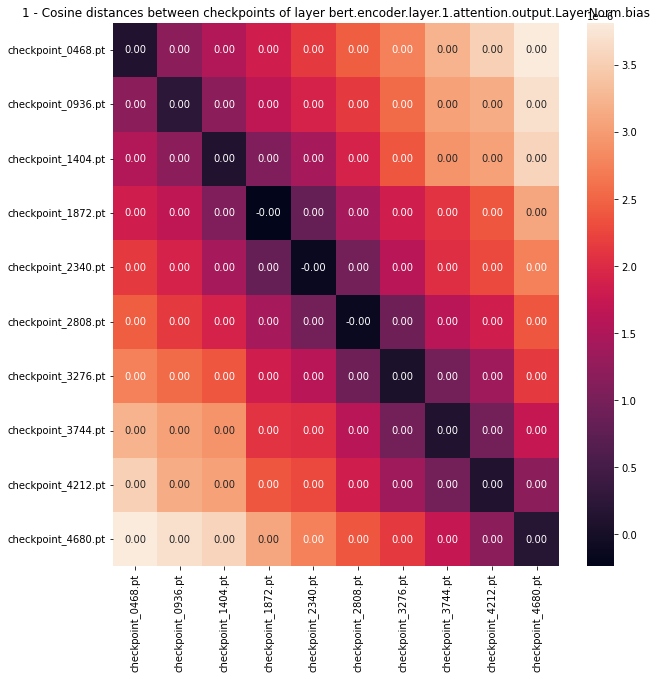

In [33]:
plot_checkpoints_similarity_per_layer(checkpoint_files, checkpoints, minus_cosine_distance, '1 - Cosine', layer_num=30)

In [34]:
get_num_layers(checkpoints[0])

201

In [35]:
[name for name,weights in checkpoints[0].named_parameters()]

['bert.embeddings.word_embeddings.weight',
 'bert.embeddings.position_embeddings.weight',
 'bert.embeddings.token_type_embeddings.weight',
 'bert.embeddings.LayerNorm.weight',
 'bert.embeddings.LayerNorm.bias',
 'bert.encoder.layer.0.attention.self.query.weight',
 'bert.encoder.layer.0.attention.self.query.bias',
 'bert.encoder.layer.0.attention.self.key.weight',
 'bert.encoder.layer.0.attention.self.key.bias',
 'bert.encoder.layer.0.attention.self.value.weight',
 'bert.encoder.layer.0.attention.self.value.bias',
 'bert.encoder.layer.0.attention.output.dense.weight',
 'bert.encoder.layer.0.attention.output.dense.bias',
 'bert.encoder.layer.0.attention.output.LayerNorm.weight',
 'bert.encoder.layer.0.attention.output.LayerNorm.bias',
 'bert.encoder.layer.0.intermediate.dense.weight',
 'bert.encoder.layer.0.intermediate.dense.bias',
 'bert.encoder.layer.0.output.dense.weight',
 'bert.encoder.layer.0.output.dense.bias',
 'bert.encoder.layer.0.output.LayerNorm.weight',
 'bert.encoder.layer

In [36]:
layers = ['bert.embeddings',
 *(f'bert.encoder.layer.{i:d}.' for i in range(12)),
 'bert.pooler',
 'classifier',]
layers

['bert.embeddings',
 'bert.encoder.layer.0.',
 'bert.encoder.layer.1.',
 'bert.encoder.layer.2.',
 'bert.encoder.layer.3.',
 'bert.encoder.layer.4.',
 'bert.encoder.layer.5.',
 'bert.encoder.layer.6.',
 'bert.encoder.layer.7.',
 'bert.encoder.layer.8.',
 'bert.encoder.layer.9.',
 'bert.encoder.layer.10.',
 'bert.encoder.layer.11.',
 'bert.pooler',
 'classifier']

In [37]:
def bin_params_by_layer(model, prefix_list, disable_tqdm=False):
    """
    Returns a list of flattened tensors, one tensor for each layer of the model containing all the parameters of all operations of this layer.
    
    Parameters:
    model (torch.nn.Module): The model.
    prefix (list of str): The list of layer prefixes.
    """
    # Initialize a dictionary to hold parameters for each layer
    layer_list_params = {p: [] for p in prefix_list}

    # Loop over the named parameters of the model
    for name, param in tqdm(model.named_parameters(), desc="Flatten the layer weights", disable=disable_tqdm):
        # Check each layer prefix to see if it matches the start of the parameter name
        match = False
        for p in prefix_list:
            if name.startswith(p):
                # If it matches, add the parameter to the list for this layer
                layer_list_params[p].append(param)
                match = True
                break
        if not match:
            #log warning
            warnings.warn(f"Parameter {name} did't match any layer in the list", UserWarning)

    # Flatten the parameters for each layer and return as a list
    # print(layer_params.values())
    layer_params = {name: torch.cat([p.view(-1) for p in params]) for (name,params) in layer_list_params.items()}

    return layer_params

In [40]:
bins = bin_params_by_layer(checkpoints[0],layers)

Flatten the layer weights: 201it [00:00, 176852.34it/s]


In [48]:
bins

{'bert.embeddings': tensor([-0.0102, -0.0615, -0.0265,  ..., -0.0302,  0.0215,  0.0305],
        grad_fn=<CatBackward0>),
 'bert.encoder.layer.0.': tensor([-0.0167,  0.0257, -0.0266,  ..., -0.1075,  0.0042,  0.0285],
        grad_fn=<CatBackward0>),
 'bert.encoder.layer.1.': tensor([ 0.0310, -0.0255,  0.0044,  ..., -0.0504, -0.0264, -0.0484],
        grad_fn=<CatBackward0>),
 'bert.encoder.layer.2.': tensor([ 0.0843,  0.0147, -0.0629,  ..., -0.0251, -0.0082, -0.0256],
        grad_fn=<CatBackward0>),
 'bert.encoder.layer.3.': tensor([ 0.0595, -0.0276,  0.0018,  ..., -0.0297, -0.0090, -0.0493],
        grad_fn=<CatBackward0>),
 'bert.encoder.layer.4.': tensor([ 0.0840,  0.0494,  0.0221,  ..., -0.0305, -0.0425, -0.0517],
        grad_fn=<CatBackward0>),
 'bert.encoder.layer.5.': tensor([-0.0096,  0.0008,  0.0343,  ..., -0.0337, -0.0409, -0.0579],
        grad_fn=<CatBackward0>),
 'bert.encoder.layer.6.': tensor([-0.0250,  0.0477, -0.0148,  ..., -0.0538, -0.0255, -0.0476],
        grad_fn

In [41]:
print({name:param.shape for name,param in bins.items()})

{'bert.embeddings': torch.Size([23837184]), 'bert.encoder.layer.0.': torch.Size([7087872]), 'bert.encoder.layer.1.': torch.Size([7087872]), 'bert.encoder.layer.2.': torch.Size([7087872]), 'bert.encoder.layer.3.': torch.Size([7087872]), 'bert.encoder.layer.4.': torch.Size([7087872]), 'bert.encoder.layer.5.': torch.Size([7087872]), 'bert.encoder.layer.6.': torch.Size([7087872]), 'bert.encoder.layer.7.': torch.Size([7087872]), 'bert.encoder.layer.8.': torch.Size([7087872]), 'bert.encoder.layer.9.': torch.Size([7087872]), 'bert.encoder.layer.10.': torch.Size([7087872]), 'bert.encoder.layer.11.': torch.Size([7087872]), 'bert.pooler': torch.Size([590592]), 'classifier': torch.Size([1538])}


In [42]:
def plot_checkpoints_similarity_per_layer_average(checkpoint_files, checkpoints, prefix_list, sim, sim_name, fmt=".2f", disable_tqdm=False):

    # Initialize an empty array for the distances
    dist_matrix = np.zeros((len(checkpoints), len(checkpoints)))
    
    # Compute pairwise Hausdorff distances for each layer
    for i, checkpoint_i in enumerate(tqdm(checkpoints, disable=disable_tqdm)):
        bins_i = bin_params_by_layer(checkpoint_i,layers)
        for j, checkpoint_j in enumerate(checkpoints):
            if j >= i:  # To avoid double calculation
                bins_j = bin_params_by_layer(checkpoint_j,layers, disable=disable_tqdm)
                
                layer_distances = []
                for (name_i, param_i), (name_j, param_j) in zip(bins_i.items(), bins_j.items()):
                    if name_i == name_j:  # Should always be True
                        # Flatten the weights to 1D vectors
                        weights_i = param_i.detach().numpy().flatten().reshape(1, -1)
                        weights_j = param_j.detach().numpy().flatten().reshape(1, -1)
                        # Compute Hausdorff distance for this layer
                        distance = sim(weights_i, weights_j)
                        layer_distances.append(distance)
                    else:
                        warnings.warn(f"Mismatching parameters \"{name_i}\" and \"{name_j}\"", UserWarning)
                        
                # Sum or average the layer distances to get a single distance value for the pair of checkpoints
                dist_matrix[i, j] = sum(layer_distances)/len(layer_distances)
                dist_matrix[j, i] = dist_matrix[i, j]  # The distance is symmetric
    
    # Plot the distances as a heatmap
    plt.figure(figsize=(10, 10))
    sns.heatmap(dist_matrix, annot=True, fmt=fmt, xticklabels=checkpoint_files, yticklabels=checkpoint_files)
    plt.title(f'{sim_name} distances between checkpoints')
    plt.show()

In [43]:
def plot_checkpoints_similarity(checkpoint_files, checkpoints, prefix_list, sim, sim_name, fmt=".2f", factor = 1., disable_tqdm=False):

    # Initialize an empty array for the distances
    dist_matrix = np.zeros((len(prefix_list), len(checkpoints)))
    
    bins = [bin_params_by_layer(checkpoint_i, prefix_list, disable_tqdm=disable_tqdm) for checkpoint_i in checkpoints]
    
    for i, layer in enumerate(tqdm(prefix_list, disable=disable_tqdm)):
        for j, bin_j in enumerate(bins):
            weights_i, weights_j = bins[0][layer].detach().numpy().reshape(-1, 1), bin_j[layer].detach().numpy().reshape(-1, 1)
            dist_matrix[i, j] = sim(weights_i, weights_j)*factor/weights_i.size
    
    # Plot the distances as a heatmap
    plt.figure(figsize=(10, 10))
    sns.heatmap(dist_matrix, annot=True, fmt=fmt, xticklabels=checkpoint_files, yticklabels=prefix_list)
    plt.title(f'{sim_name} distances between checkpoints '+ (f'Multiplied by a factor of {factor}' if factor != 1. else ''))
    plt.show()

Flatten the layer weights: 201it [00:00, 125435.96it/s]
Flatten the layer weights: 201it [00:00, 172403.91it/s]
Flatten the layer weights: 201it [00:00, 132389.31it/s]
Flatten the layer weights: 201it [00:00, 133839.51it/s]
Flatten the layer weights: 201it [00:00, 159097.02it/s]
Flatten the layer weights: 201it [00:00, 138843.07it/s]
Flatten the layer weights: 201it [00:00, 108153.32it/s]
Flatten the layer weights: 201it [00:00, 142215.77it/s]
Flatten the layer weights: 201it [00:00, 141523.44it/s]
Flatten the layer weights: 201it [00:00, 139095.05it/s]
Flatten the layer weights: 201it [00:00, 150089.92it/s]
Flatten the layer weights: 201it [00:00, 150170.13it/s]
Flatten the layer weights: 201it [00:00, 184193.82it/s]
Flatten the layer weights: 201it [00:00, 134630.33it/s]
Flatten the layer weights: 201it [00:00, 132932.06it/s]
Flatten the layer weights: 201it [00:00, 193627.72it/s]
Flatten the layer weights: 201it [00:00, 199350.93it/s]
Flatten the layer weights: 201it [00:00, 159427.

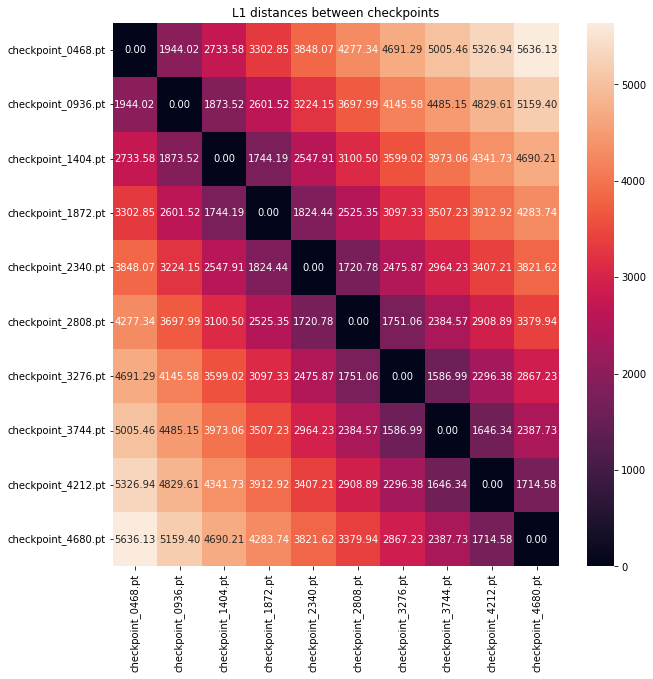

In [46]:
plot_checkpoints_similarity_per_layer_average(checkpoint_files, checkpoints, layers, l1_distance, 'L1', fmt=".2f", disable_tqdm=True)

In [ ]:
plot_checkpoints_similarity_per_layer_average(checkpoint_files, checkpoints, layers, l2_distance, 'L2', disable_tqdm=True, fmt=".2f")

In [ ]:
plot_checkpoints_similarity(checkpoint_files, checkpoints, layers, l1_distance, "L1", factor=1000, disable_tqdm=True)

In [ ]:
plot_checkpoints_similarity(checkpoint_files, checkpoints, layers, l2_distance, "L2", factor=1000, disable_tqdm=True)

In [ ]:
plot_checkpoints_similarity(checkpoint_files, checkpoints, layers, minus_cosine_distance, "1 - Cosine", factor=1000, disable_tqdm=True)

In [ ]:
def plot_distributions(arrays, titles):
    """ Plot distributions of arrays in separate subplots.
    
    Args:
        arrays (list of np.ndarray): List of arrays to plot.
        titles (list of str): Titles for each subplot.
    """
    
    if len(arrays) != len(titles):
        raise ValueError("The length of arrays and titles must be equal.")
    
    n = len(arrays)
    fig, axs = plt.subplots(n, 1, figsize=(10, 5*n))
    
    for i, array in enumerate(arrays):
        sns.histplot(array, kde=True, ax=axs[i])
        axs[i].set_title(titles[i])

    plt.tight_layout()
    plt.show()


In [81]:
def plot_grouped_distributions(array_group, group_titles, plot_titles, downsample=None, disable_tqdm=False):
    """ Plot distributions of arrays grouped on the same axes.

    Args:
        array_group (list of list of np.ndarray): Group of arrays to plot.
        group_titles (list of str): Titles for each group.
        plot_titles (list of list of str): Titles for each plot in the group.
    """

    if len(array_group) != len(group_titles) or len(array_group) != len(plot_titles):
        raise ValueError("The lengths of array groups, group titles, and plot titles must be equal.")

    n = len(array_group)
    fig, axs = plt.subplots(n, 1, figsize=(10, 5*n))

    for i, array_list in tqdm(enumerate(array_group), desc="Plotting array_list", disable=disable_tqdm):
        for j, array in enumerate(array_list):
            if downsample is not None and len(array) > downsample:
                array = np.random.choice(array, size=downsample, replace=False)
            sns.histplot(array, kde=True, ax=axs[i], label=plot_titles[i][j])
        axs[i].set_title(group_titles[i])
        axs[i].legend()

    plt.tight_layout()
    plt.show()

def plot_grouped_kde(array_group, group_titles, plot_titles, downsample=None, disable_tqdm=False):
    """ Plot KDEs of downsampled arrays grouped on the same axes.

    Args:
        array_group (list of list of np.ndarray): Group of arrays to plot.
        group_titles (list of str): Titles for each group.
        plot_titles (list of list of str): Titles for each plot in the group.
        downsample (int): Number of points to downsample to. Default is None, ie not downsample.
    """

    if len(array_group) != len(group_titles) or len(array_group) != len(plot_titles):
        raise ValueError("The lengths of array groups, group titles, and plot titles must be equal.")

    n = len(array_group)
    fig, axs = plt.subplots(n, 1, figsize=(10, 5*n))

    for i, array_list in enumerate(tqdm(array_group, disable=disable_tqdm, desc="Plotting KDE")):
        for j, array in enumerate(array_list):
            # Downsample data
            if downsample is not None and len(array) > downsample:
                array = np.random.choice(array, size=downsample, replace=False)
            sns.kdeplot(array, ax=axs[i], label=plot_titles[i][j])
        axs[i].set_title(group_titles[i])
        axs[i].legend()

    plt.tight_layout()
    plt.show()



def plot_checkpoints_grouped_distributions_per_layer(checkpoint_files, checkpoints, prefix_list, downsample=None, disable_tqdm=False):

    # Initialize an empty array for the distances
    dist_matrix = np.zeros((len(prefix_list), len(checkpoints)))
    
    bins = [bin_params_by_layer(checkpoint_i, prefix_list, disable_tqdm=disable_tqdm) for checkpoint_i in checkpoints]
    
    group_titles = []
    array_group = []
    plot_titles = []

    for layer in tqdm(prefix_list, disable=disable_tqdm, desc="Calculating layers"):
        group_titles.append(layer)
        array_list = []
        plot_title_list = []
        for checkpoint_name, bin in zip(checkpoint_files, bins):
            array_list.append(bin[layer].detach().numpy())
            plot_title_list.append(f"Distribution of {checkpoint_name}")
        array_group.append(array_list)    
        plot_titles.append(plot_title_list)

    return plot_grouped_kde(array_group, group_titles, plot_titles, downsample=downsample, disable_tqdm=disable_tqdm)

Plotting array_list: 3it [00:00,  9.32it/s]


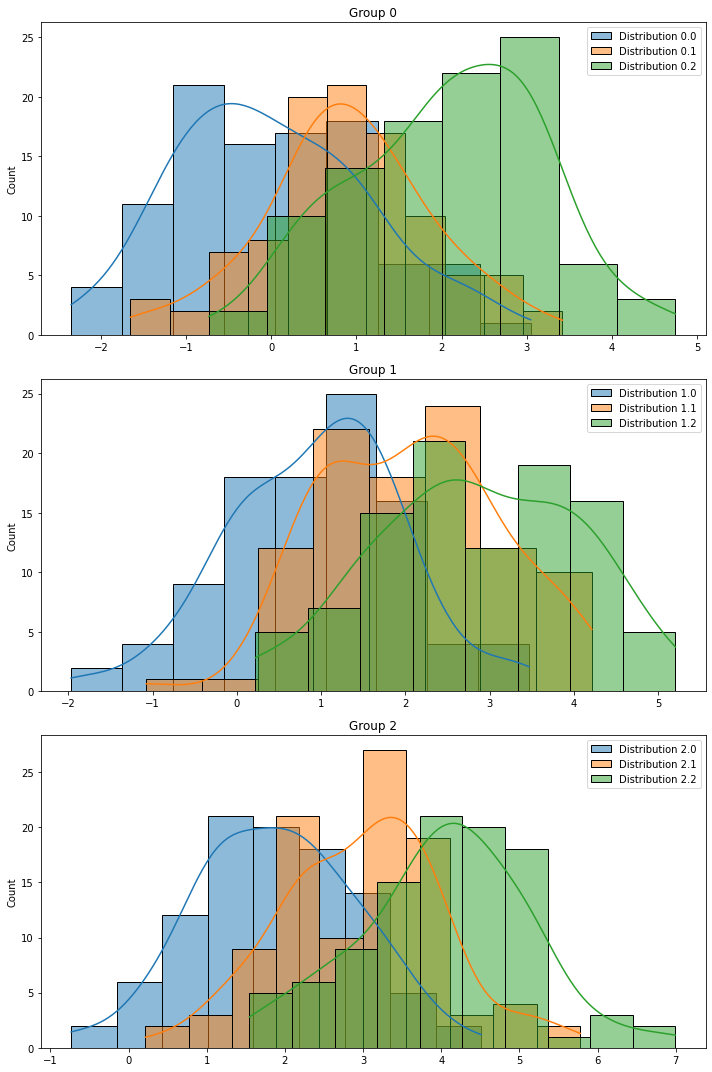

In [73]:
# Test the function with random data
array_group = [[np.random.normal(loc=i+j, scale=1, size=1000) for j in range(3)] for i in range(3)]
group_titles = [f'Group {i}' for i in range(3)]
plot_titles = [[f'Distribution {i}.{j}' for j in range(3)] for i in range(3)]
plot_grouped_distributions(array_group, group_titles, plot_titles, downsample=100)

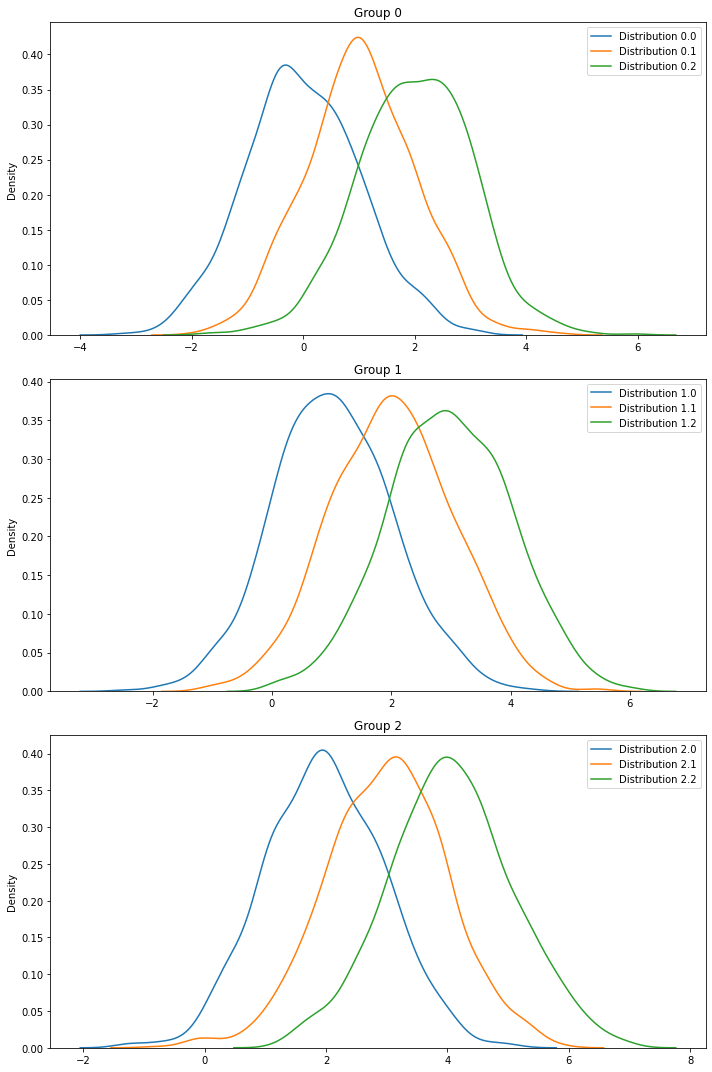

In [74]:
# Test the function with random data
plot_grouped_kde(array_group, group_titles, plot_titles)

Flatten the layer weights: 201it [00:00, 182321.61it/s]
Flatten the layer weights: 201it [00:00, 174005.18it/s]
Flatten the layer weights: 201it [00:00, 161165.19it/s]
Flatten the layer weights: 201it [00:00, 170073.65it/s]
Flatten the layer weights: 201it [00:00, 151166.42it/s]
Flatten the layer weights: 201it [00:00, 166315.86it/s]
Flatten the layer weights: 201it [00:00, 135604.81it/s]
Flatten the layer weights: 201it [00:00, 171771.62it/s]
Flatten the layer weights: 201it [00:00, 165434.68it/s]
Flatten the layer weights: 201it [00:00, 168476.24it/s]


BINS: [{'bert.embeddings': tensor([-0.0102, -0.0615, -0.0265,  ..., -0.0302,  0.0215,  0.0305],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.0.': tensor([-0.0167,  0.0257, -0.0266,  ..., -0.1075,  0.0042,  0.0285],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.1.': tensor([ 0.0310, -0.0255,  0.0044,  ..., -0.0504, -0.0264, -0.0484],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.2.': tensor([ 0.0843,  0.0147, -0.0629,  ..., -0.0251, -0.0082, -0.0256],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.3.': tensor([ 0.0595, -0.0276,  0.0018,  ..., -0.0297, -0.0090, -0.0493],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.4.': tensor([ 0.0840,  0.0494,  0.0221,  ..., -0.0305, -0.0425, -0.0517],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.5.': tensor([-0.0096,  0.0008,  0.0343,  ..., -0.0337, -0.0409, -0.0579],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.6.': tensor([-0.0250,  0.0477, -0.0148,  ..., -0.0538, -0.0255, -0.0476],
       grad_fn=<CatBac

Plotting KDE: 100%|██████████| 15/15 [00:40<00:00,  2.68s/it]


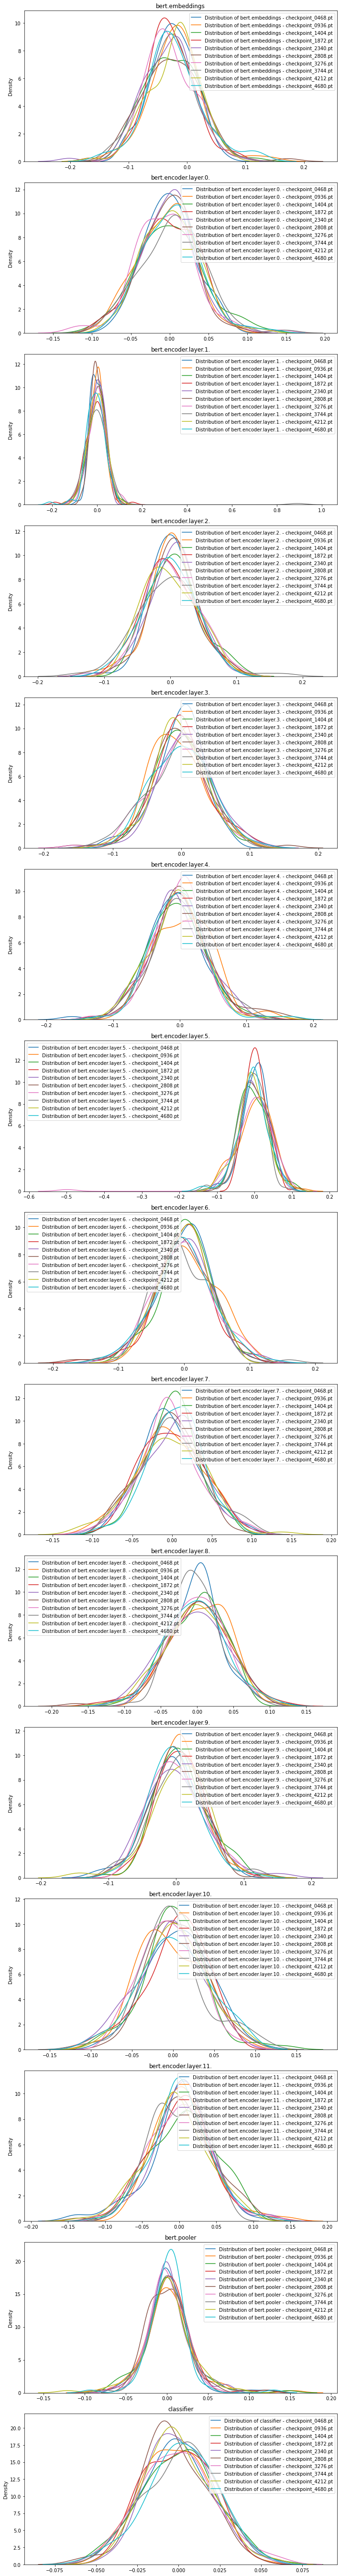

In [77]:
plot_checkpoints_grouped_distributions_per_layer(checkpoint_files, checkpoints, layers, downsample=100, disable_tqdm=False)

Flatten the layer weights: 201it [00:00, 116219.34it/s]
Flatten the layer weights: 201it [00:00, 127023.52it/s]
Flatten the layer weights: 201it [00:00, 128927.22it/s]
Flatten the layer weights: 201it [00:00, 134201.70it/s]
Flatten the layer weights: 201it [00:00, 136549.26it/s]
Flatten the layer weights: 201it [00:00, 134052.33it/s]
Flatten the layer weights: 201it [00:00, 129800.63it/s]
Flatten the layer weights: 201it [00:00, 130282.04it/s]
Flatten the layer weights: 201it [00:00, 142793.89it/s]
Flatten the layer weights: 201it [00:00, 138934.59it/s]


BINS: [{'bert.embeddings': tensor([-0.0102, -0.0615, -0.0265,  ..., -0.0302,  0.0215,  0.0305],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.0.': tensor([-0.0167,  0.0257, -0.0266,  ..., -0.1075,  0.0042,  0.0285],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.1.': tensor([ 0.0310, -0.0255,  0.0044,  ..., -0.0504, -0.0264, -0.0484],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.2.': tensor([ 0.0843,  0.0147, -0.0629,  ..., -0.0251, -0.0082, -0.0256],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.3.': tensor([ 0.0595, -0.0276,  0.0018,  ..., -0.0297, -0.0090, -0.0493],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.4.': tensor([ 0.0840,  0.0494,  0.0221,  ..., -0.0305, -0.0425, -0.0517],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.5.': tensor([-0.0096,  0.0008,  0.0343,  ..., -0.0337, -0.0409, -0.0579],
       grad_fn=<CatBackward0>), 'bert.encoder.layer.6.': tensor([-0.0250,  0.0477, -0.0148,  ..., -0.0538, -0.0255, -0.0476],
       grad_fn=<CatBac

Plotting KDE: 100%|██████████| 15/15 [00:40<00:00,  2.68s/it]


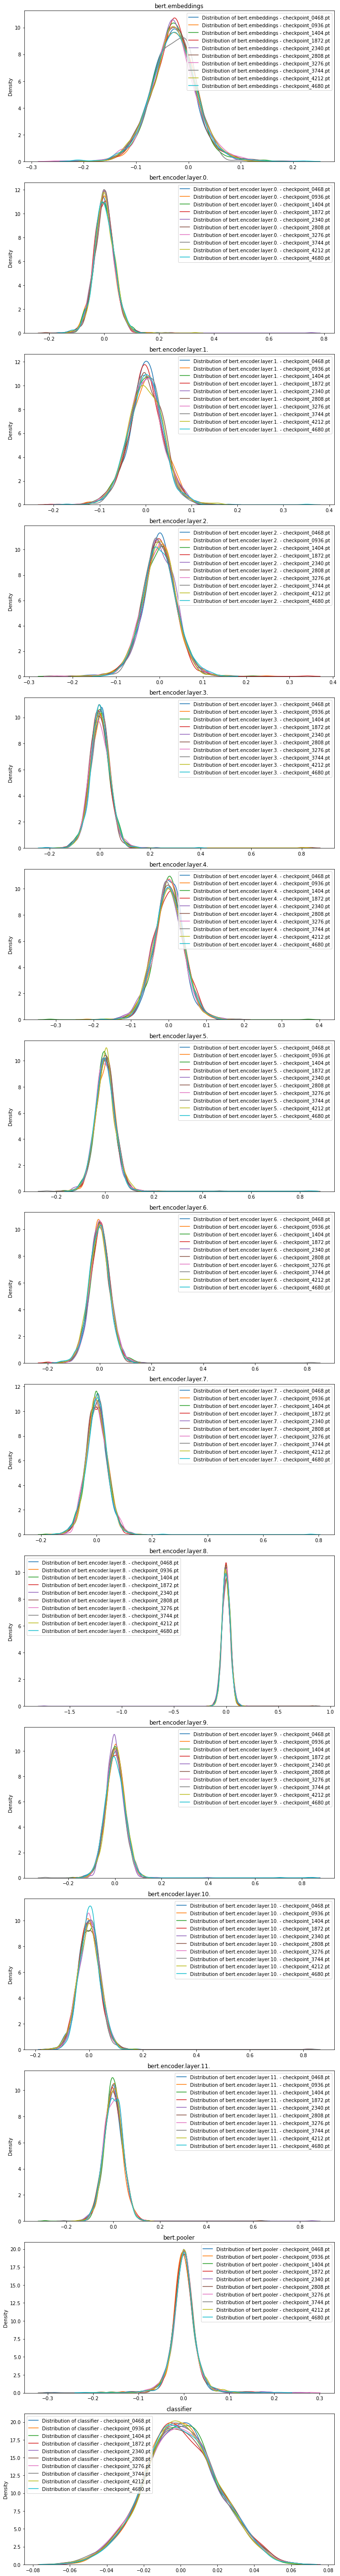

In [78]:
plot_checkpoints_grouped_distributions_per_layer(checkpoint_files, checkpoints, layers, downsample=1000, disable_tqdm=False)

Flatten the layer weights: 201it [00:00, 165629.69it/s]
Flatten the layer weights: 201it [00:00, 133648.56it/s]
Flatten the layer weights: 201it [00:00, 132285.44it/s]
Flatten the layer weights: 201it [00:00, 139624.89it/s]
Flatten the layer weights: 201it [00:00, 144383.47it/s]
Flatten the layer weights: 201it [00:00, 135583.00it/s]
Flatten the layer weights: 201it [00:00, 130767.04it/s]
Flatten the layer weights: 201it [00:00, 134201.70it/s]
Flatten the layer weights: 201it [00:00, 143866.06it/s]
Flatten the layer weights: 201it [00:00, 81850.01it/s]
Plotting KDE: 100%|██████████| 15/15 [00:39<00:00,  2.65s/it]


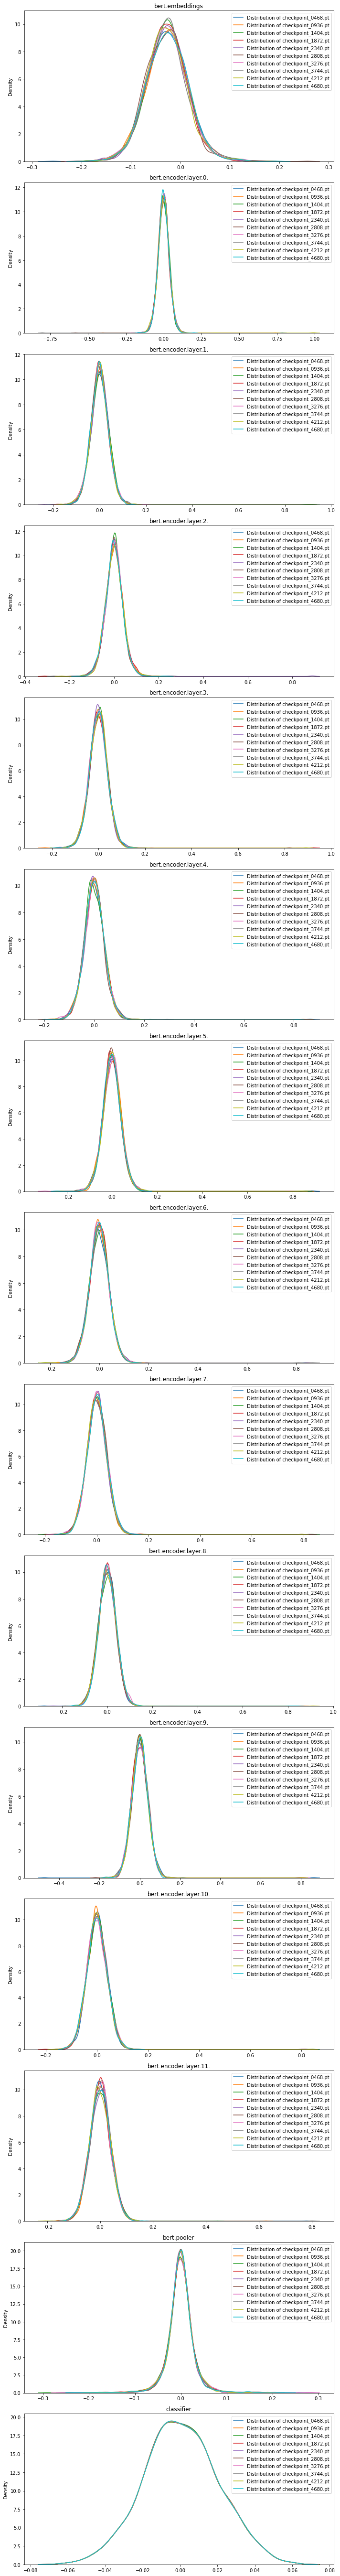

In [82]:
plot_checkpoints_grouped_distributions_per_layer(checkpoint_files, checkpoints, layers, downsample=2000, disable_tqdm=False)

Flatten the layer weights: 201it [00:00, 106245.13it/s]
Flatten the layer weights: 201it [00:00, 172403.91it/s]
Flatten the layer weights: 201it [00:00, 177897.26it/s]
Flatten the layer weights: 201it [00:00, 183034.11it/s]
Flatten the layer weights: 201it [00:00, 181419.22it/s]
Flatten the layer weights: 201it [00:00, 180757.96it/s]
Flatten the layer weights: 201it [00:00, 183233.02it/s]
Flatten the layer weights: 201it [00:00, 177822.21it/s]
Flatten the layer weights: 201it [00:00, 178689.09it/s]
Flatten the layer weights: 201it [00:00, 171631.74it/s]
Plotting KDE: 100%|██████████| 15/15 [00:44<00:00,  2.97s/it]


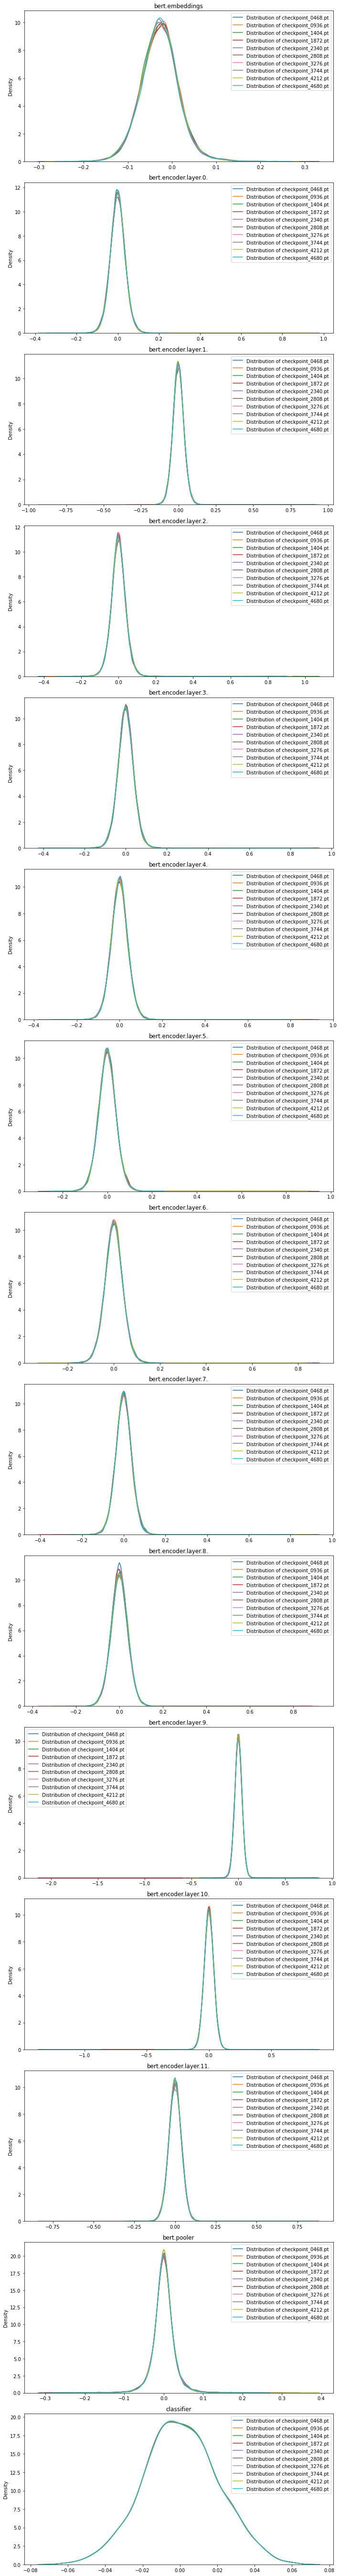

In [83]:
plot_checkpoints_grouped_distributions_per_layer(checkpoint_files, checkpoints, layers, downsample=10000, disable_tqdm=False)

Flatten the layer weights: 201it [00:00, 131892.23it/s]
Flatten the layer weights: 201it [00:00, 136571.38it/s]
Flatten the layer weights: 201it [00:00, 134437.11it/s]
Flatten the layer weights: 201it [00:00, 135365.30it/s]
Plotting KDE: 100%|██████████| 15/15 [00:18<00:00,  1.25s/it]


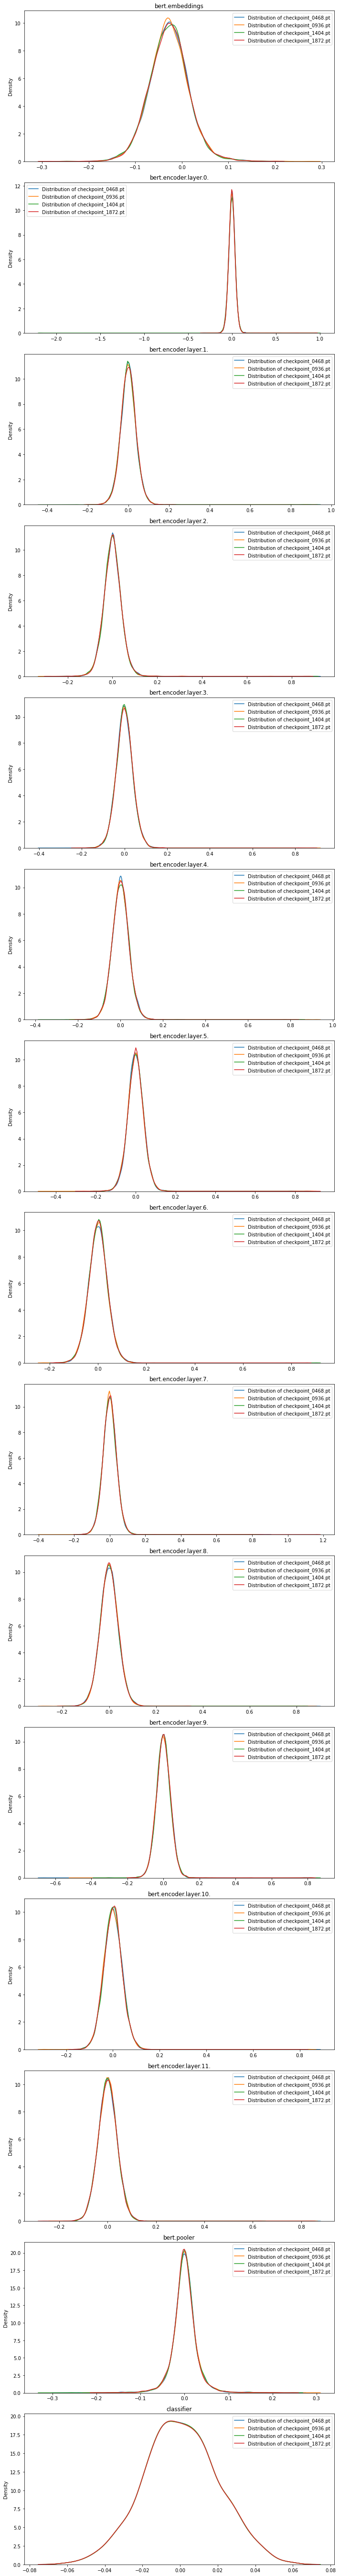

In [84]:
plot_checkpoints_grouped_distributions_per_layer(checkpoint_files[0:4], checkpoints[0:4], layers, downsample=10000, disable_tqdm=False)